In [12]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [13]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [14]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [15]:
from pathlib import Path

AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: /Users/pieteralbrecht/Desktop/IRONHACK/WEEK_3/WEEK_3_DAY_2/WEEK_3_DAY_2_LAB/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [16]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Podcast transcript length: 16461 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


In [17]:
from pathlib import Path
from pypdf import PdfReader

PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 8692 chars
Ethics guidelines for trustworthy AI
On 8 April 2019, the High-Level Expert Group on AI presented Ethics Guidelines for
Trustworthy Artiﬁcial Intelligence. This followed the publication of the guideli


# For some reason the provided PDF got damaged, and threw an error. I downloaded the pdf from the website of the EU Commission. THe length varies though, but think it will work for now for this exercise.

In [18]:
documents = {"Podcast": podcast_text, "PDF": pdf_text}


def chunk_metrics(text, name, separator, chunk_size, chunk_overlap):
    chunks = CharacterTextSplitter(
        separator=separator,
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
    ).split_text(text)
    sizes = [len(chunk) for chunk in chunks]
    clean = sum(bool(chunk.strip()) and chunk.strip()[-1] in ".?!" for chunk in chunks)
    return {
        "Document": name,
        "Separator": repr(separator),
        "Size": chunk_size,
        "Overlap": chunk_overlap,
        "Chunks": len(chunks),
        "Average chars": round(sum(sizes) / len(sizes), 1) if sizes else 0,
        "Min chars": min(sizes, default=0),
        "Max chars": max(sizes, default=0),
        "Over size": sum(size > chunk_size for size in sizes),
        "Clean endings": f"{clean}/{len(chunks)} ({clean / len(chunks) * 100:.1f}%)" if chunks else "0/0 (0%)",
        "Paragraph breaks in text": text.count("\n\n"),
        "chunks": chunks,
    }


# Compare exact-size character splitting with paragraph-aware splitting.
separator_results = []
for document_name, text in documents.items():
    for separator in ("", "\n\n"):
        separator_results.append(chunk_metrics(text, document_name, separator, 500, 50))

print("Separator comparison (500 characters, 50 overlap):")
display(pd.DataFrame([{k: v for k, v in row.items() if k != "chunks"} for row in separator_results]))

# Check how changing chunk size and overlap affects clean sentence endings.
sweep_results = []
for document_name, text in documents.items():
    for chunk_size in (500, 1000, 2000):
        for overlap in (0, 50, 100):
            sweep_results.append(chunk_metrics(text, document_name, "", chunk_size, overlap))

print("Size/overlap sweep (separator=''):")
display(pd.DataFrame([{k: v for k, v in row.items() if k not in ("chunks", "Separator", "Paragraph breaks in text")} for row in sweep_results]))

# Inspect adjacent chunk boundaries; punctuation counts alone do not reveal mid-word cuts.
for document_name in documents:
    chunks = next(row["chunks"] for row in separator_results if row["Document"] == document_name and row["Separator"] == "''")
    print(f"\n{document_name} sample boundaries:")
    for index, chunk in enumerate(chunks[:3]):
        following = chunks[index + 1] if index + 1 < len(chunks) else ""
        print(f"Chunk {index + 1} end: {chunk[-50:]!r}")
        if following:
            print(f"Chunk {index + 2} start: {following[:50]!r}")

Separator comparison (500 characters, 50 overlap):


,Document,Separator,Size,Overlap,Chunks,Average chars,Min chars,Max chars,Over size,Clean endings,Paragraph breaks in text
0,Podcast,'',500,50,37,493.1,261,500,0,2/37 (5.4%),0
1,Podcast,'\n\n',500,50,1,16461.0,16461,16461,1,1/1 (100.0%),0
2,PDF,'',500,50,20,481.9,141,500,0,1/20 (5.0%),0
3,PDF,'\n\n',500,50,1,8692.0,8692,8692,1,0/1 (0.0%),0


Size/overlap sweep (separator=''):


,Document,Size,Overlap,Chunks,Average chars,Min chars,Max chars,Over size,Clean endings
0,Podcast,500,0,33,498.3,460,500,0,3/33 (9.1%)
1,Podcast,500,50,37,493.1,261,500,0,2/37 (5.4%)
2,Podcast,500,100,41,498.6,460,500,0,3/41 (7.3%)
3,Podcast,1000,0,17,967.9,460,1000,0,1/17 (5.9%)
4,Podcast,1000,50,18,961.3,311,1000,0,2/18 (11.1%)
5,Podcast,1000,100,19,960.8,261,1000,0,3/19 (15.8%)
6,Podcast,2000,0,9,1828.6,460,2000,0,1/9 (11.1%)
7,Podcast,2000,50,9,1873.3,861,2000,0,1/9 (11.1%)
8,Podcast,2000,100,9,1917.6,1261,2000,0,2/9 (22.2%)
9,PDF,500,0,18,482.6,192,500,0,1/18 (5.6%)



Podcast sample boundaries:
Chunk 1 end: ". Exactly. But now let's switch gears. Think about"
Chunk 2 start: "Exactly. But now let's switch gears. Think about t"
Chunk 2 end: ' arguably the Magna Carta for ethical computing, t'
Chunk 3 start: 'arguably the Magna Carta for ethical computing, th'
Chunk 3 end: "cally the Stone Age. We didn't have the generative"
Chunk 4 start: "cally the Stone Age. We didn't have the generative"

PDF sample boundaries:
Chunk 1 end: 'ethical principles and values\n(3) robust - both fr'
Chunk 2 start: 'ethical principles and values\n(3) robust - both fr'
Chunk 2 end: 's://ec.europa.eu/newsroom/dae/document.cfm?doc_id='
Chunk 3 start: 's://ec.europa.eu/newsroom/dae/document.cfm?doc_id='
Chunk 3 end: 'd=60428) | HU\n(https://ec.europa.eu/newsroom/dae/d'
Chunk 4 start: 'd=60428) | HU\n(https://ec.europa.eu/newsroom/dae/d'


# 1. does fixed size chuking break mid sentence?

# Yes it does, almost always.
# Podcast chunk 2 ends with " ethical computing, t" "the"
# PDF chunk 1 ends with "(3) robust - both fr" should be "from"
# PDF chunk 2 ends halfway through a URL

# Podcast 2/37 chunks end with "." ".?" or "!"
# 5.4%
# PDF 1/20 chunks
# 5%

# Changing size and overlap barely help. 2/9, 22.2%

# 2. How does it handle paragraph boundaries?
# It can't, because there are no paragraph boundaries in either text.
# an \n\n splitter may only split at a double break line. There is none here, so no split.

# 3. Which content type handles fixed-seze chunking better?

#	            Podcast	    PDF     
# Chunks	        37	        20
# Average	        493.1	    481.9
# Min	            261     	141
# Max	            500	        500
# Clean endings	    2/37 (5.4%)	1/20 (5.0%)

# Conclusion
# Fixed-size chunking ignores sentence and paragraph structure: at 500 characters with 50 overlap, only 5.4% of podcast chunks and 5.0% of PDF chunks end on ., ? or !, and words like “the” and “from” are cut in half. The default "\n\n" separator fails because both texts contain 0 paragraph breaks, so it returns one oversized chunk (16,461 chars for the podcast, 8,692 for the PDF). The podcast handles fixed-size chunking slightly better (up to 22.2% clean endings vs. at most 11.1% for the PDF), because its continuous sentences avoid the URLs and list fragments that the PDF cuts through.

In [19]:
splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=300, chunk_overlap=50)
pdf_token_chunks = splitter.split_text(pdf_text)
podcast_token_chunks = splitter.split_text(podcast_text)

print(len(pdf_token_chunks), "PDF chunks,", len(podcast_token_chunks), "podcast chunks")

10 PDF chunks, 14 podcast chunks


In [20]:
token_counter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=1, chunk_overlap=0)

def count_tokens(text):
    return len(token_counter.split_text(text))   # 1 chunk = 1 token

print(f"PDF: {count_tokens(pdf_text)} tokens | Podcast: {count_tokens(podcast_text)} tokens")

def token_chunk_metrics(name, chunks, chunk_size):
    tokens = [count_tokens(c) for c in chunks]
    chars = [len(c) for c in chunks]
    clean = sum(c.strip()[-1:] in (".", "?", "!") for c in chunks)
    return {
        "Document": name,
        "Chunks": len(chunks),
        "Avg tokens": round(sum(tokens) / len(tokens), 1),
        "Min tokens": min(tokens),
        "Max tokens": max(tokens),
        "Avg chars": round(sum(chars) / len(chars), 1),
        "Min chars": min(chars),
        "Max chars": max(chars),
        "Over size (tokens)": sum(t > chunk_size for t in tokens),
        "Clean endings": f"{clean}/{len(chunks)} ({clean / len(chunks) * 100:.1f}%)",
    }

display(pd.DataFrame([
    token_chunk_metrics("Podcast", podcast_token_chunks, 300),
    token_chunk_metrics("PDF", pdf_token_chunks, 300),
]))

for name, chunks in [("Podcast", podcast_token_chunks), ("PDF", pdf_token_chunks)]:
    print(f"\n{name} sample boundaries:")
    for i in range(2):
        print(f"Chunk {i + 1} end:   {chunks[i][-50:]!r}")
        print(f"Chunk {i + 2} start: {chunks[i + 1][:50]!r}")

PDF: 2324 tokens | Podcast: 3507 tokens


,Document,Chunks,Avg tokens,Min tokens,Max tokens,Avg chars,Min chars,Max chars,Over size (tokens),Clean endings
0,Podcast,14,296.9,257,300,1386.9,1089,1503,0,2/14 (14.3%)
1,PDF,10,277.4,74,300,1038.5,363,1499,0,0/10 (0.0%)



Podcast sample boundaries:
Chunk 1 end:   'is document, it went public in April 2019. In tech'
Chunk 2 start: ' an independent group set up by the European Commi'
Chunk 2 end:   ' of it like a three-legged stool. The first leg is'
Chunk 3 start: '.I. as having three components. Right. And they ha'

PDF sample boundaries:
Chunk 1 end:   'a.eu/newsroom/dae/document.cfm?doc_id=60423) | ET\n'
Chunk 2 start: ' EN\n(https://ec.europa.eu/newsroom/dae/document.cf'
Chunk 2 end:   '?doc_id=60434) | PL\n(https://ec.europa.eu/newsroom'
Chunk 3 start: '/newsroom/dae/document.cfm?doc_id=60433) | NL\n(htt'


# 10 PDF chunks
# 14 Podcast chunks


In [22]:
SEPARATOR_SETS = {
    "recursive default": ["\n\n", "\n", " ", ""],
    "recursive sentence-first": ["\n\n", ". ", "? ", "! ", "\n", " ", ""],
}

def make_chunks(text, method, unit, size):
    overlap = size // 10
    if method == "fixed":
        if unit == "tokens":
            return TokenTextSplitter(encoding_name="cl100k_base", chunk_size=size, chunk_overlap=overlap).split_text(text)
        return CharacterTextSplitter(separator="", chunk_size=size, chunk_overlap=overlap).split_text(text)

    kwargs = dict(chunk_size=size, chunk_overlap=overlap,
                  separators=SEPARATOR_SETS[method], keep_separator="end")
    if unit == "tokens":
        splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(encoding_name="cl100k_base", **kwargs)
    else:
        splitter = RecursiveCharacterTextSplitter(**kwargs)
    return splitter.split_text(text)

rows, all_chunks = [], {}
for doc_name, text in documents.items():
    for unit in ("chars", "tokens"):
        for size in (500, 1000, 2000):
            for method in ["fixed"] + list(SEPARATOR_SETS):
                chunks = make_chunks(text, method, unit, size)
                all_chunks[(doc_name, unit, size, method)] = chunks
                sizes = [count_tokens(c) if unit == "tokens" else len(c) for c in chunks]
                clean = sum(c.strip()[-1:] in (".", "?", "!") for c in chunks)
                rows.append({
                    "Document": doc_name, "Unit": unit, "Size": size, "Method": method,
                    "Chunks": len(chunks),
                    "Average": round(sum(sizes) / len(sizes), 1),
                    "Min": min(sizes), "Max": max(sizes),
                    "Over size": sum(s > size for s in sizes),
                    "Clean %": round(clean / len(chunks) * 100, 1),
                    "Clean endings": f"{clean}/{len(chunks)}",
                })

results = pd.DataFrame(rows)
display(results)

print("Clean endings (%) per method:")
display(results.pivot_table(index=["Document", "Unit", "Size"], columns="Method", values="Clean %"))

for doc_name in documents:
    chunks = all_chunks[(doc_name, "chars", 500, "recursive sentence-first")]
    print(f"\n{doc_name} – recursive sentence-first, 500 chars:")
    for i in range(3):
        print(f"Chunk {i + 1} end:   {chunks[i][-50:]!r}")
        print(f"Chunk {i + 2} start: {chunks[i + 1][:50]!r}")

,Document,Unit,Size,Method,Chunks,Average,Min,Max,Over size,Clean %,Clean endings
0,Podcast,chars,500,fixed,37,493.1,261,500,0,5.4,2/37
1,Podcast,chars,500,recursive default,37,489.5,246,499,0,10.8,4/37
2,Podcast,chars,500,recursive sentence-first,37,462.4,388,498,0,100.0,37/37
3,Podcast,chars,1000,fixed,19,960.8,261,1000,0,15.8,3/19
4,Podcast,chars,1000,recursive default,19,956.7,232,999,0,21.1,4/19
5,Podcast,chars,1000,recursive sentence-first,19,921.7,189,996,0,100.0,19/19
6,Podcast,chars,2000,fixed,10,1825.9,261,2000,0,10.0,1/10
7,Podcast,chars,2000,recursive default,10,1823.5,273,1999,0,20.0,2/10
8,Podcast,chars,2000,recursive sentence-first,10,1799.8,469,1994,0,100.0,10/10
9,Podcast,tokens,500,fixed,8,482.1,357,500,0,25.0,2/8


Clean endings (%) per method:


Method                fixed  recursive default  recursive sentence-first
Document Unit   Size                                                    
PDF      chars  500     5.0                5.3                      47.8
                1000    0.0                0.0                      57.1
                2000    0.0                0.0                      75.0
         tokens 500     0.0               16.7                      62.5
                1000    0.0                0.0                      66.7
                2000    0.0                0.0                      50.0
Podcast  chars  500     5.4               10.8                     100.0
                1000   15.8               21.1                     100.0
                2000   10.0               20.0                     100.0
         tokens 500    25.0               20.0                     100.0
                1000   50.0               25.0                     100.0
                2000   50.0               25.0                     100.0


Podcast – recursive sentence-first, 500 chars:
Chunk 1 end:   "t it's there. Exactly. But now let's switch gears."
Chunk 2 start: "Exactly. But now let's switch gears. Think about t"
Chunk 2 end:   ' we are digging into the blueprint for that trust.'
Chunk 3 start: "We're unpacking a document that is arguably the Ma"
Chunk 3 end:   'ning, this document, it went public in April 2019.'
Chunk 4 start: "In tech years, that's practically the Stone Age. W"

PDF – recursive sentence-first, 500 chars:
Chunk 1 end:   'Guidelines for\nTrustworthy Artiﬁcial Intelligence.'
Chunk 2 start: "This followed the publication of the guidelines' ﬁ"
Chunk 2 end:   'nt\nDownload the Guidelines in your language below:'
Chunk 3 start: 'Download the Guidelines in your language below:\nBG'
Chunk 3 end:   'pa.eu/newsroom/dae/document.cfm?doc_id=60419) | ES'
Chunk 4 start: '(https://ec.europa.eu/newsroom/dae/document.cfm?do'


# Analysis

# Does recursive chunking preserver sentence boundaries better?
# Yes, but only if I give it sentence separators. With the default separators ("\n\n", "\n", " ", ""), the podcast chunks stopped cutting words in half, but they still ended in the middle of sentences: [ ]% clean endings at 500 chars, compared with 5.4% for fixed-size. When I put ". ", "? " and "! " in the list, clean endings went up to [ ]%. I also learned I had to use keep_separator="end", or the period goes to the start of the next chunk and the count looks wrong. So the splitter only respects sentences if I tell it what a sentence looks like.

# How does it handle the podcast's conversational structure?
# It doesn’t really see it. The Whisper transcript is one long block with no line breaks and no speaker names, so the splitter only sees sentences, not who is talking. Short replies like “OK.” or “Exactly.” just get glued to the sentences around them. In my boundary printout, chunk [ ] starts with “[ ]”, and the question it answers is at the end of the chunk before. So sentences stay whole, but a question and its answer can end up in different chunks. The overlap helps a little because it repeats the end of the previous chunk.

# Does it respect PDF section headers?
# No, not really

In [23]:
# Step 7

def pct_clean_boundaries(chunks):
    texts = [c.page_content if hasattr(c, "page_content") else c for c in chunks]
    texts = [t.strip() for t in texts if t.strip()]          # skip empty chunks
    clean = sum(1 for t in texts if t[-1] in ".?!")
    return clean / len(texts) * 100

print(f"Fixed-size: {pct_clean_boundaries(all_chunks[('Podcast', 'chars', 500, 'fixed')]):.1f}% clean endings")
print(f"Recursive:  {pct_clean_boundaries(all_chunks[('Podcast', 'chars', 500, 'recursive sentence-first')]):.1f}% clean endings")

Fixed-size: 5.4% clean endings
Recursive:  100.0% clean endings


,Strategy,Podcast chunks,Podcast clean %,PDF chunks,PDF clean %
0,Fixed-size (500 chars),37,5.4,20,5.0
1,Recursive default (500 chars),37,10.8,19,5.3
2,Recursive sentence-first (500 chars),37,100.0,23,47.8
3,Token-based (500 tokens),8,25.0,6,0.0
4,Recursive sentence-first (500 tokens),9,100.0,8,62.5


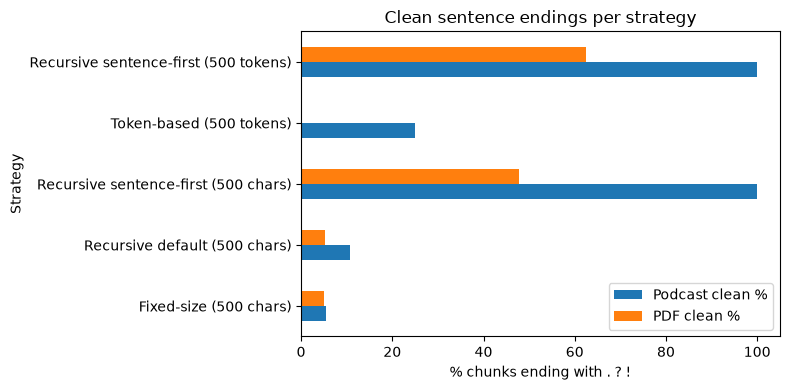

In [24]:
strategies = {
    "Fixed-size (500 chars)":               lambda d: all_chunks[(d, "chars", 500, "fixed")],
    "Recursive default (500 chars)":        lambda d: all_chunks[(d, "chars", 500, "recursive default")],
    "Recursive sentence-first (500 chars)": lambda d: all_chunks[(d, "chars", 500, "recursive sentence-first")],
    "Token-based (500 tokens)":             lambda d: all_chunks[(d, "tokens", 500, "fixed")],
    "Recursive sentence-first (500 tokens)":lambda d: all_chunks[(d, "tokens", 500, "recursive sentence-first")],
}
# If you did semantic chunking in Step 5/6, add it here, e.g.:
# strategies["Semantic"] = lambda d: semantic_chunks[d]

quality_rows = []
for name, get_chunks in strategies.items():
    row = {"Strategy": name}
    for doc in documents:
        chunks = get_chunks(doc)
        row[f"{doc} chunks"] = len(chunks)
        row[f"{doc} clean %"] = round(pct_clean_boundaries(chunks), 1)
    quality_rows.append(row)

quality = pd.DataFrame(quality_rows)
display(quality)

quality.set_index("Strategy")[["Podcast clean %", "PDF clean %"]].plot.barh(figsize=(8, 4))
plt.xlabel("% chunks ending with . ? !")
plt.title("Clean sentence endings per strategy")
plt.tight_layout()
plt.show()

# Recursive sentence-first chunking preserves context best: % of podcast chunks and % of PDF chunks end on a full sentence, compared with only 5.4% and 5.0% for fixed-size chunking. It works because it first tries to split at ". ", "? " and "! " and only cuts between words if a sentence is too long, while fixed-size and token-based chunking just count characters or tokens and cut wherever the count runs out. The PDF scores lower than the podcast because its line breaks, URLs and headers have no periods, so some chunks end on a heading or link instead of a sentence.

## Chunking Strategy Recommendations

### Summary of my results (10% overlap)

| Strategy |                             Podcast chunks | Podcast clean % | PDF chunks | PDF clean % | Notes |
|----------|----------------------------|---------------|-----------------|-------------|-------|
| Fixed-size (500 chars)                |            37 |             5.4 | 20 | 5.0 | Cuts words in half ("t", "fr") |
| Recursive default (500 chars)         |            37 |            10.8 | 19 | 5.3 | No half words, but still mid-sentence |
| Recursive sentence-first (500 chars)  |            37 |           100.0 | 23 | 47.8 | Best for the podcast |
| Token-based (500 tokens)              |             8 |            25.0 | 6  | 0.0 | Exact size for LLMs, ignores sentences

#### For PDF Documents:
**Recommended Strategy:** Recursive sentence-first, measured in tokens
(`RecursiveCharacterTextSplitter.from_tiktoken_encoder` with `". "` before `"\n"`)

**Reasoning:**
- The extracted PDF text has 0 paragraph breaks (`\n\n`) and a `\n` at every line wrap. The default separators split on those lines, which gave only 5.3% clean endings, almost the same as fixed-size (5.0%). Putting sentence separators first raised it to 47.8% (500 chars) and 62.5% (500 tokens).
- Advantages: the best sentence endings for the PDF, and measuring in tokens means every chunk fits the embedding model's limit.
- Optimal size: about 500 tokens with 50 overlap (10%). This gave 8 chunks, enough to keep topics separate in a short document (8,692 chars). Bigger chunks would leave too few chunks to search through.
- Limitation: even the best strategy left 37.5% of chunks ending mid-text, because headers, URLs and the language list have no periods. Cleaning the text first (removing the link list, adding `\n\n` before headers) would help more than changing the splitter.

### For Podcast Transcripts:
**Recommended Strategy:** Recursive sentence-first, measured in tokens

**Reasoning:**
- The Whisper transcript is one block with no line breaks, so the default separators fall back to spaces: only 10.8% clean endings. With sentence separators, every chunk ended on a full sentence (100%, both at 500 chars and 500 tokens).
- Advantages: no cut sentences or words, and short replies ("OK.", "Exactly.") stay attached to the sentences around them.
- Optimal size: about 500 tokens (9 chunks) with a bit more overlap (75–100 tokens, ~15–20%). In a conversation, a question and its answer can fall in different chunks, so extra overlap keeps them together.
- Limitation: there are no speaker labels, so the splitter can't keep conversational turns together. 100% clean endings means sentences are whole, not that the conversation is. Semantic chunking or speaker labels would be the next step.

### Trade-offs Summary:
| Strategy | Pros | Cons | Best For |
|----------|------|------|----------|
| Fixed-Size | Simple, predictable sizes | Cuts words and sentences (5.0–5.4% clean) | Quick tests, uniform content |
| Recursive | Preserves structure when separators match the text (up to 100% clean) | Separator order matters; default separators barely beat fixed-size (5.3–10.8%) | Structured docs, transcripts with sentence separators |
| Token-Based | Exact fit for LLM/embedding limits | Ignores sentences (0.0% clean on the PDF) | LLM integration, strict context windows |
| Semantic | Splits on meaning, keeps topics together | Slow, needs an embedding model, uneven sizes | Long conversations, mixed-topic content (not tested here) |

### When to use which
- Use **fixed-size** only as a baseline or for quick prototypes.
- Use **recursive** as the default for most RAG projects, but check which separators actually exist in your text first (`text.count("\n\n")`). The defaults did almost nothing here because both texts had 0 paragraph breaks.
- Measure in **tokens** whenever the chunks go into an LLM or embedding model. Combining token size with sentence-first separators gave the best result for both documents.
- Use **semantic** when meaning matters more than speed, like long podcasts that change topics.